# RiboFlow Human Reference: Version 4 vs Version 3

v4 removes duplicated sequence from the reference, so fewer reads are discarded as multimappers:

1. Read-through genes are removed. They share exons with the genes they span.
2. Transcripts that lie inside a longer transcript are removed.
3. Bicistronic transcripts (one RNA annotated as two genes) keep only the gene with the longer CDS.

We then map two ribosome profiling experiments to v3 and v4 and compare the results.

The steps are in `generate_appris_reference.py`. Run the cells from `transcriptome/human/v4/scripts/`
in the `ribopy` environment (see `v3/scripts/README.md`).

## v4 selection pipeline

From `generate_appris_reference.py`:

1. `pick_best_appris_transcripts`: MANE_Select + PRINCIPAL per gene, otherwise the longest PRINCIPAL.
2. `pick_protein_coding_transcripts`.
3. `remove_readthrough_genes` (new in v4).
4. `pick_transcripts_with_proper_codons`: proper start and stop codons.
5. `remove_contained_transcripts` (new in v4): drops transcripts that lie entirely inside a longer selected transcript.
6. `collapse_identical_transcripts` (new in v4): keeps one transcript per group of identical exon structures, the one with the longest CDS.
7. Write FASTA, BED and length files, build the Bowtie2 index.

v3 did not have steps 3, 5 and 6.

In [1]:
import gzip, hashlib, subprocess, collections
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import ribopy
from ribopy import Ribo
%matplotlib inline

REF = Path("../riboflow_annot_and_ref")
RAW = Path("../raw/annotation")
GTF = RAW / "gencode.v50.annotation.gtf.gz"
FASTA = REF / "appris_human_v4_selected.fa.gz"
V3_FASTA = Path("../../v3/riboflow_annot_and_ref/appris_human_v3_selected.fa.gz")
REGIONS = REF / "appris_human_v4_actual_regions.bed"
V3_OVERLAP = Path("../../v3/riboflow_annot_and_ref/containment/overlap_fraction.tsv")
RIBO3 = Path("../comparison/all_v3.ribo")
RIBO4 = Path("../comparison/all_v4.ribo")
print("inputs present:", all(p.exists() for p in (GTF, FASTA, V3_FASTA, REGIONS, V3_OVERLAP, RIBO3, RIBO4)))

inputs present: True


## 1. Read-through genes

GENCODE tags a gene `readthrough_gene` when it is transcribed across two neighboring genes.
Its transcript contains most of the exons of both genes, joined by a new splice junction.

We remove the read-through genes to remove shared duplicated sequence, to increases the mappability of the individual genes.

In [2]:
awk = (r'$3=="gene" && $9 ~ /tag "readthrough_gene"/'
       r'{match($9,/gene_type "[^"]*"/); print substr($9,RSTART+11,RLENGTH-12)}')
out = subprocess.run(f"gunzip -c {GTF} | awk -F'\t' '{awk}'",
                     shell=True, capture_output=True, text=True).stdout.split()
print("read-through genes removed:", len(out))
print("by gene_type:", collections.Counter(out))

read-through genes removed: 665
by gene_type: Counter({'protein_coding': 665})


In [3]:
# example
awk2 = (r'$3=="gene" && $9 ~ /gene_name "(ABCF2-H2BK1|ABCF2|H2BK1)"/'
        r'{match($9,/gene_name "[^"]*"/); nm=substr($9,RSTART+11,RLENGTH-12);'
        r' print nm"\t"$1":"$4"-"$5"("$7")\tspan="($5-$4+1)}')
print(subprocess.run(f"gunzip -c {GTF} | awk -F'\t' '{awk2}'",
                     shell=True, capture_output=True, text=True).stdout)

H2BK1	chr7:151207416-151210488(-)	span=3073
ABCF2-H2BK1	chr7:151207837-151227166(-)	span=19330
ABCF2	chr7:151211484-151227264(-)	span=15781



## 2. Bicistronic transcripts

Four pairs of genes share one identical RNA, each gene with its own ORF. Keeping both would put the
same sequence in the reference twice, so we keep the gene with the longer CDS.

In [4]:
def fasta_records(path):
    header, buf = None, []
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith(">"):
                if header is not None:
                    yield header, "".join(buf)
                header, buf = line[1:].strip(), []
            else:
                buf.append(line.strip())
    yield header, "".join(buf)

# v3 has both genes of each bicistronic RNA: the same sequence with different CDS coordinates.
by_seq = collections.defaultdict(list)
for h, s in fasta_records(V3_FASTA):
    f = h.split("|")
    start, end = map(int, next(x for x in f if x.startswith("CDS:"))[4:].split("-"))
    by_seq[hashlib.md5(s.encode()).hexdigest()].append(
        {"transcript": f[0].split(".")[0], "gene": f[5], "CDS": f"{start}-{end}", "CDS length": end - start + 1})

v4_tx = {h.split("|")[0].split(".")[0] for h, _ in fasta_records(FASTA)}
bicistronic = pd.DataFrame([{**m, "kept in v4": m["transcript"] in v4_tx}
                            for members in by_seq.values()
                            if len({m["CDS"] for m in members}) > 1 and any(m["transcript"] in v4_tx for m in members)
                            for m in members])
bicistronic

,transcript,gene,CDS,CDS length,kept in v4
0,ENST00000273968,PYURF,77-421,345,True
1,ENST00000527353,PIGY,520-735,216,False
2,ENST00000715679,ENSG00000293600,17-328,312,False
3,ENST00000323146,SLC35A4,736-1710,975,True
4,ENST00000578372,SMIM10L3,210-416,207,False
5,ENST00000313324,FAM220A,477-1256,780,True
6,ENST00000247005,GDF1,1409-2527,1119,True
7,ENST00000623882,CERS1,87-1139,1053,False


`kept in v4` marks the gene we keep. All 8 transcripts are MANE_Select.

## 3. Mapping comparison: v3 vs v4

We mapped [GSM1606107](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM1606107) and
[GSM1606108](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM1606108) (HEK293, Ingolia lab,
full SRA runs) to v3 and v4 with the same RiboFlow parameters. This follows
`v3/scripts/mapping_comparison_of_v2_and_v3.ipynb`.

The ribo files store read lengths 15 to 35. We use 28 to 32 below, as in the v2 vs v3 comparison.

The `.ribo` files are in `transcriptome/human/v4/comparison/`. They are not in the repository, so
this section can only be re-run with them.

### Ribo Files

In [5]:
ribo_3_path = RIBO3
ribo_3      = Ribo(ribo_3_path, alias = ribopy.api.alias.apris_human_alias)

ribo_4_path = RIBO4
ribo_4      = Ribo(ribo_4_path, alias = ribopy.api.alias.apris_human_alias)

In [6]:
ribo_3.print_info()

Ribo File Info:
---------------
Ribo File Version : 1.0
RiboPy Version    : 0.0.1
Creation Time     : 2026-10-29 19:19:32
Reference         : appris_human_v3
Min Read Length   : 15
Max Read Length   : 35
Metagene Radius   : 50
Left Span         : 35
Right Span        : 15

Experiments:
------------ 
Name             Reads  Coverage  RNA-Seq  Metadata
GSM1606107_v3  7173937         *                   
GSM1606108_v3  8099782         *                   


In [7]:
ribo_4.print_info()

Ribo File Info:
---------------
Ribo File Version : 1.0
RiboPy Version    : 0.0.1
Creation Time     : 2026-10-29 19:21:42
Reference         : appris_human_v4
Min Read Length   : 15
Max Read Length   : 35
Metagene Radius   : 50
Left Span         : 35
Right Span        : 15

Experiments:
------------ 
Name             Reads  Coverage  RNA-Seq  Metadata
GSM1606107_v4  7412515         *                   
GSM1606108_v4  8366125         *                   


### Length Distribution

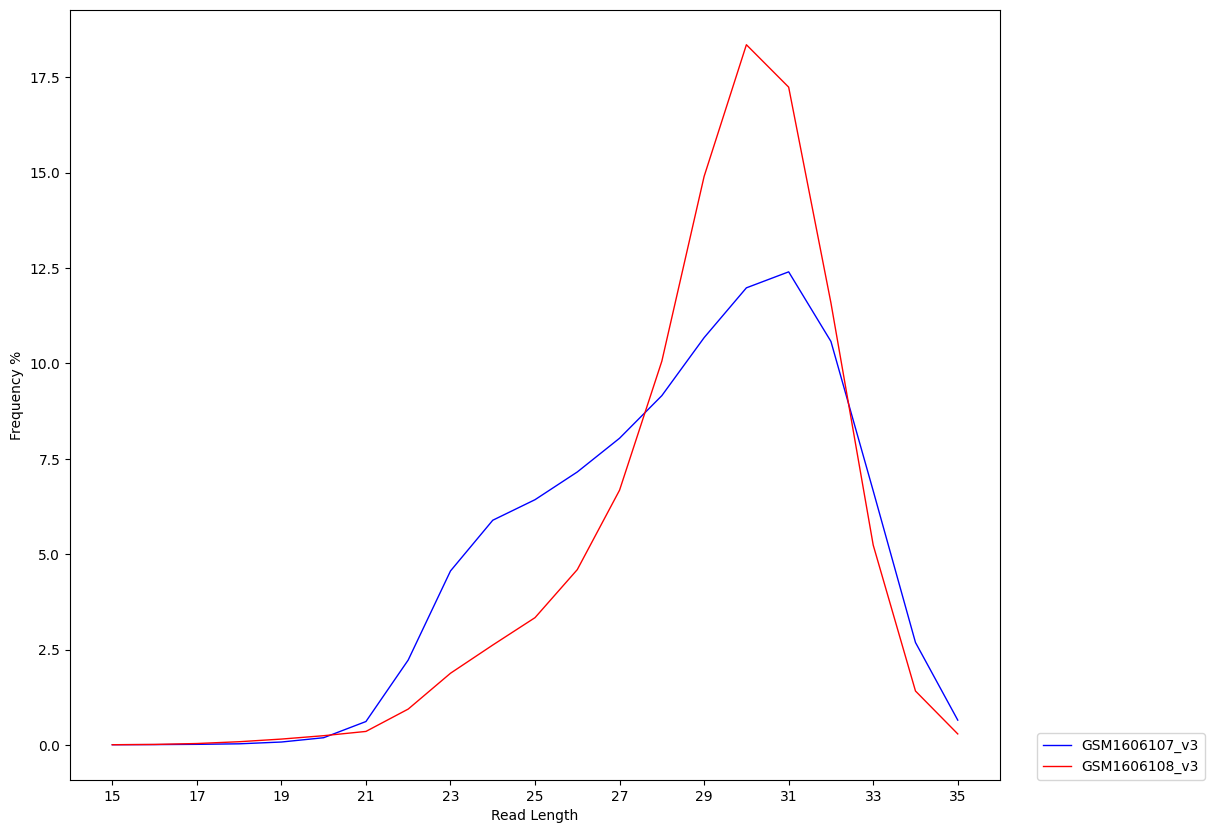

In [8]:
ribo_3.plot_lengthdist(region_type = "CDS",
                       normalize   = True,
                       experiments = ["GSM1606107_v3", "GSM1606108_v3"])

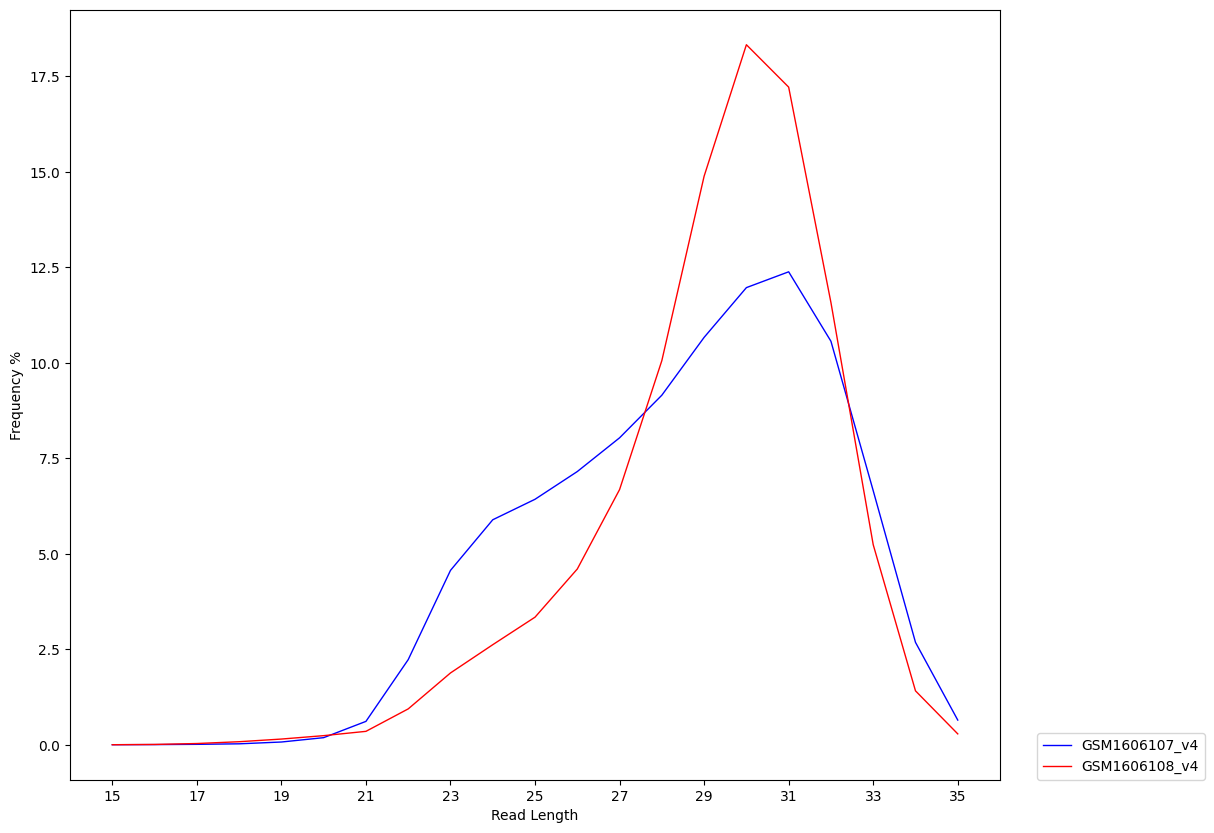

In [9]:
ribo_4.plot_lengthdist(region_type = "CDS",
                       normalize   = True,
                       experiments = ["GSM1606107_v4", "GSM1606108_v4"])

In [10]:
length_dist_3 = ribo_3.get_length_dist(
                            region_name = "CDS",
                            experiments = ["GSM1606107_v3", "GSM1606108_v3"])

length_dist_4 = ribo_4.get_length_dist(
                            region_name = "CDS",
                            experiments = ["GSM1606107_v4", "GSM1606108_v4"])

In [11]:
length_dist_3.columns = ["GSM1606107", "GSM1606108"]
length_dist_4.columns = ["GSM1606107", "GSM1606108"]

merged_length_dist = length_dist_3.merge(length_dist_4,
                                         left_index = True, right_index=True,
                                         suffixes   = ["_3", "_4"])
merged_length_dist["GSM1606107_4/3"] = (merged_length_dist["GSM1606107_4"] / merged_length_dist["GSM1606107_3"]).round(3)
merged_length_dist["GSM1606108_4/3"] = (merged_length_dist["GSM1606108_4"] / merged_length_dist["GSM1606108_3"]).round(3)
merged_length_dist

,GSM1606107_3,GSM1606108_3,GSM1606107_4,GSM1606108_4,GSM1606107_4/3,GSM1606108_4/3
read_length,,,,,,
15,324,354,337,364,1.040,1.028
16,529,883,541,902,1.023,1.022
17,967,2609,1003,2693,1.037,1.032
18,1836,6006,1898,6208,1.034,1.034
19,4852,11000,5023,11387,1.035,1.035
20,12105,17372,12589,18004,1.040,1.036
21,39330,25420,40830,26360,1.038,1.037
22,142818,67558,148006,70018,1.036,1.036
23,292625,135090,302884,139885,1.035,1.035


### Metagene

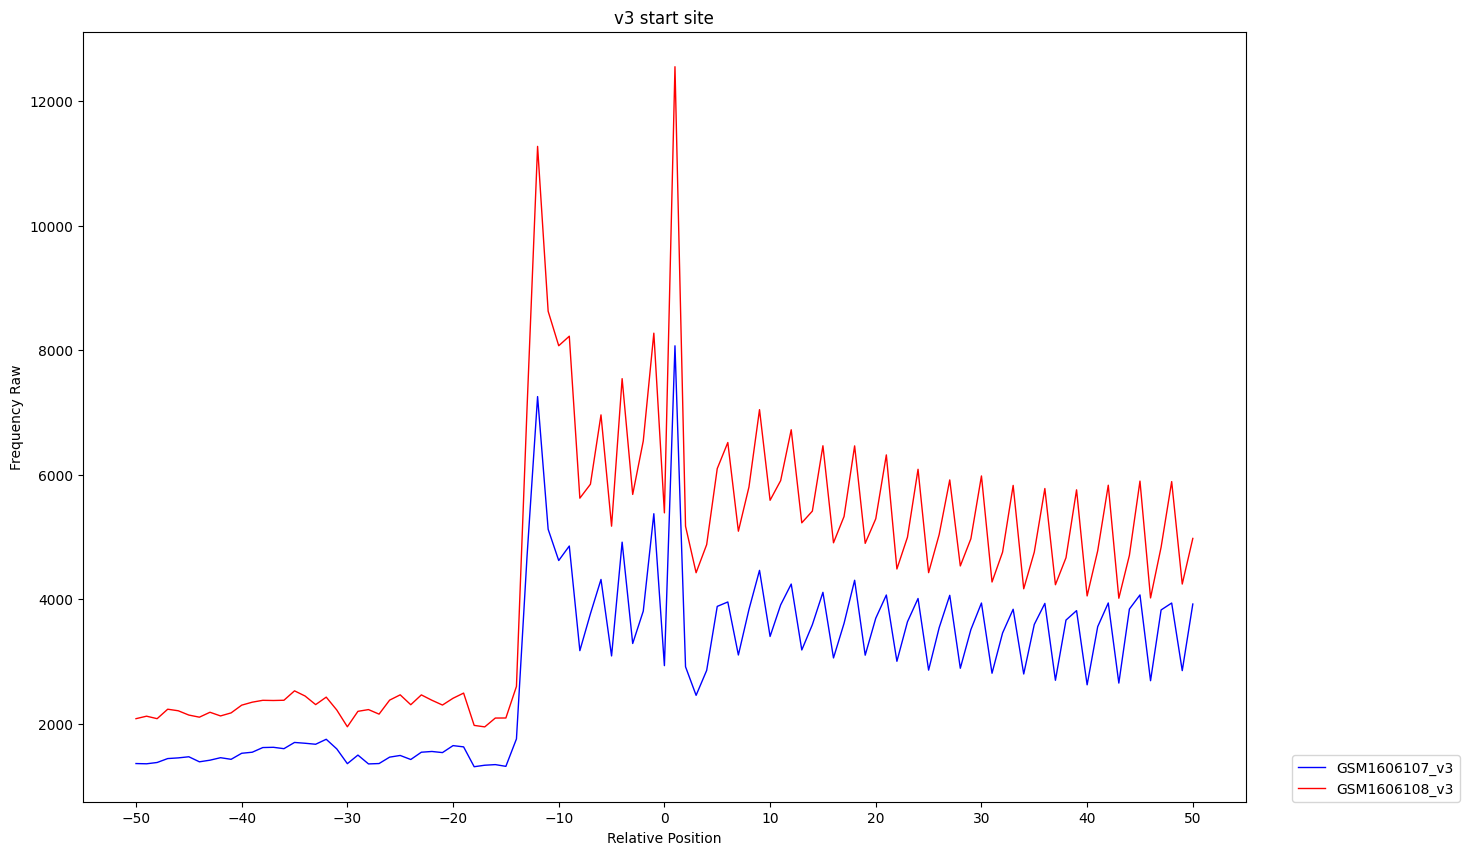

In [12]:
ribo_3.plot_metagene(site_type   = "start",
                     experiments = ["GSM1606107_v3", "GSM1606108_v3"],
                     range_lower = 28,
                     range_upper = 32,
                     title       = "v3 start site")

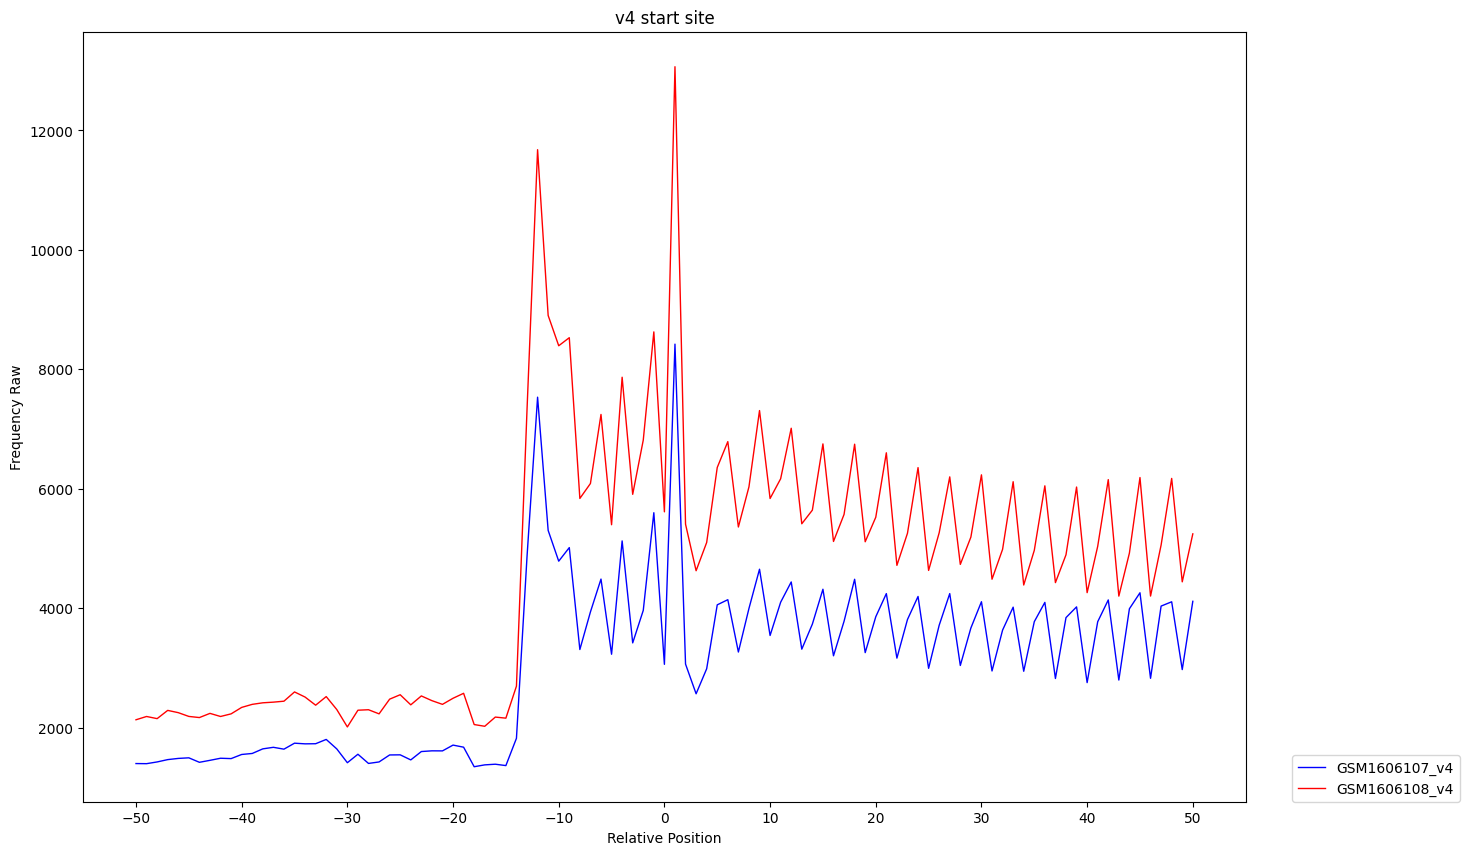

In [13]:
ribo_4.plot_metagene(site_type   = "start",
                     experiments = ["GSM1606107_v4", "GSM1606108_v4"],
                     range_lower = 28,
                     range_upper = 32,
                     title       = "v4 start site")

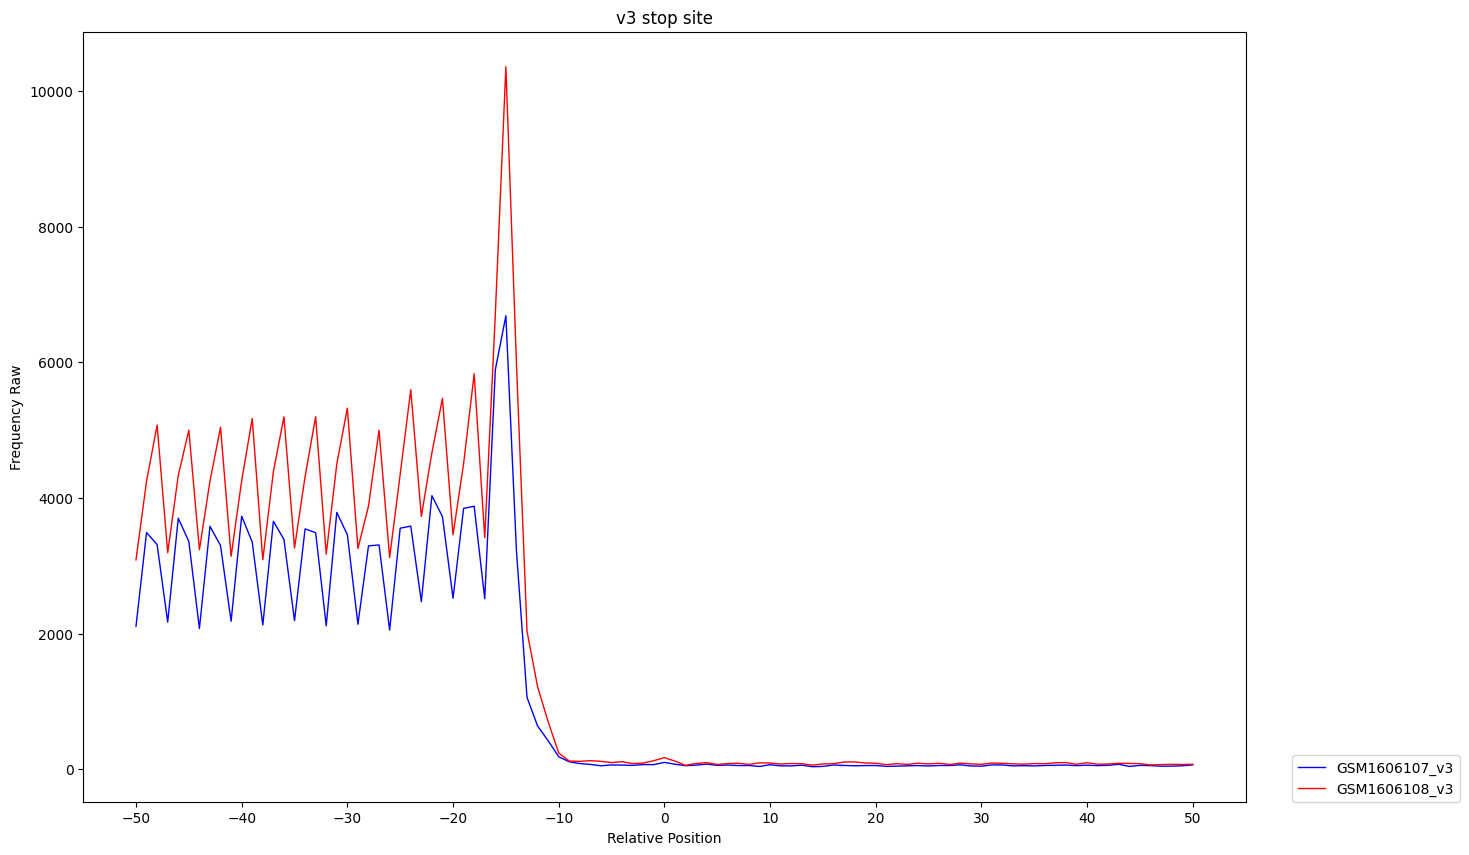

In [14]:
ribo_3.plot_metagene(site_type   = "stop",
                     experiments = ["GSM1606107_v3", "GSM1606108_v3"],
                     range_lower = 28,
                     range_upper = 32,
                     title       = "v3 stop site")

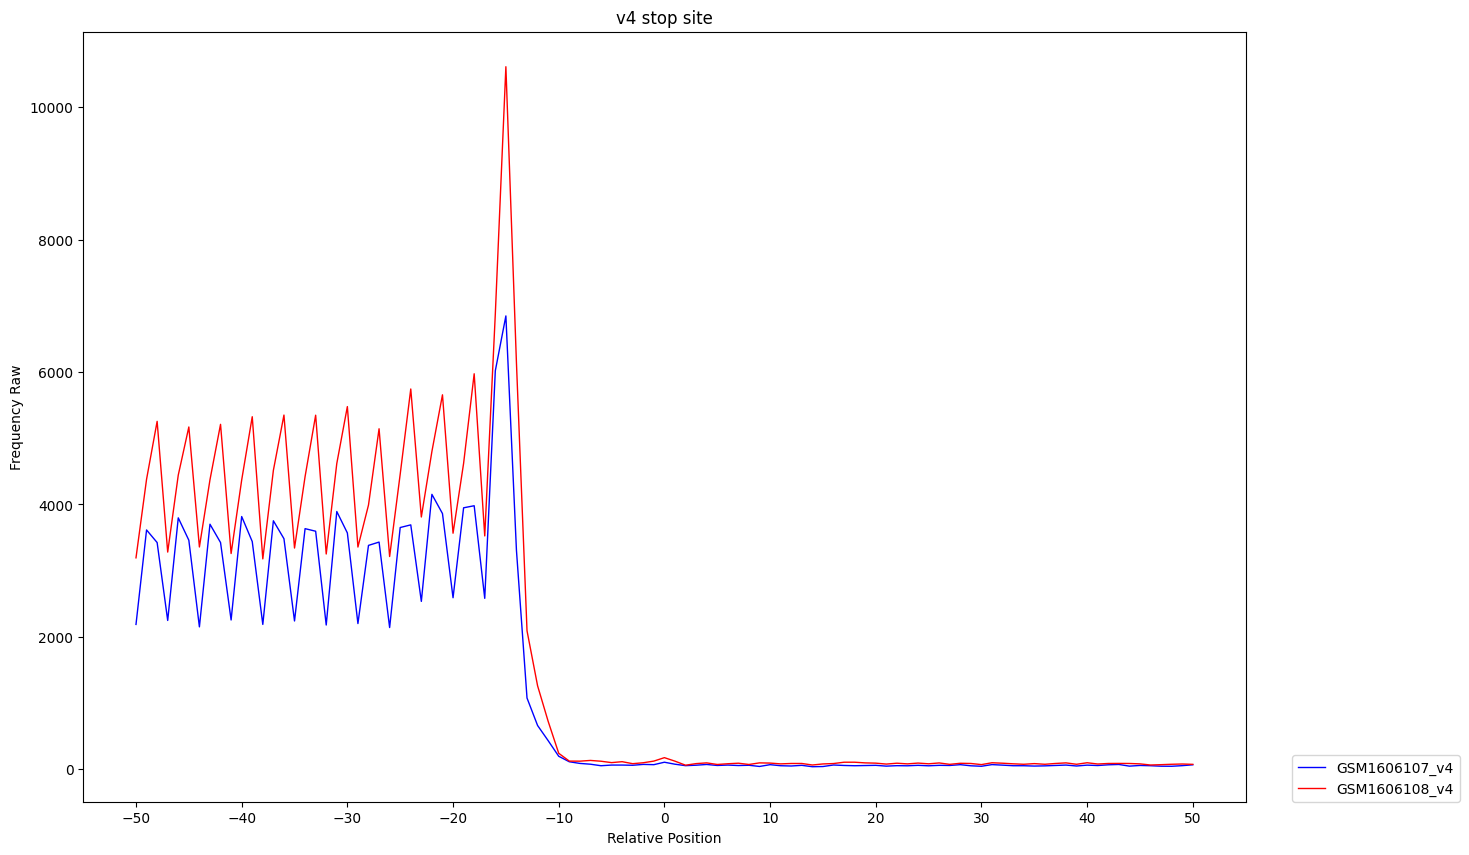

In [15]:
ribo_4.plot_metagene(site_type   = "stop",
                     experiments = ["GSM1606107_v4", "GSM1606108_v4"],
                     range_lower = 28,
                     range_upper = 32,
                     title       = "v4 stop site")

The experiments are named `<GSM>_v3` and `<GSM>_v4` inside the files. We drop the suffix so the two
tables line up. Differences are v4 − v3, so a positive value means more reads in v4.

In [16]:
strip_version = lambda e: e.rsplit("_", 1)[0]

metagene_start_3 = \
   ribo_3.get_metagene(site_type      = "start",
                       range_lower    = 28,
                       range_upper    = 32,
                       sum_lengths    = True,
                       sum_references = True
                      ).astype("int64").rename(index = strip_version)

metagene_start_4 = \
   ribo_4.get_metagene(site_type      = "start",
                       range_lower    = 28,
                       range_upper    = 32,
                       sum_lengths    = True,
                       sum_references = True
                      ).astype("int64").rename(index = strip_version)

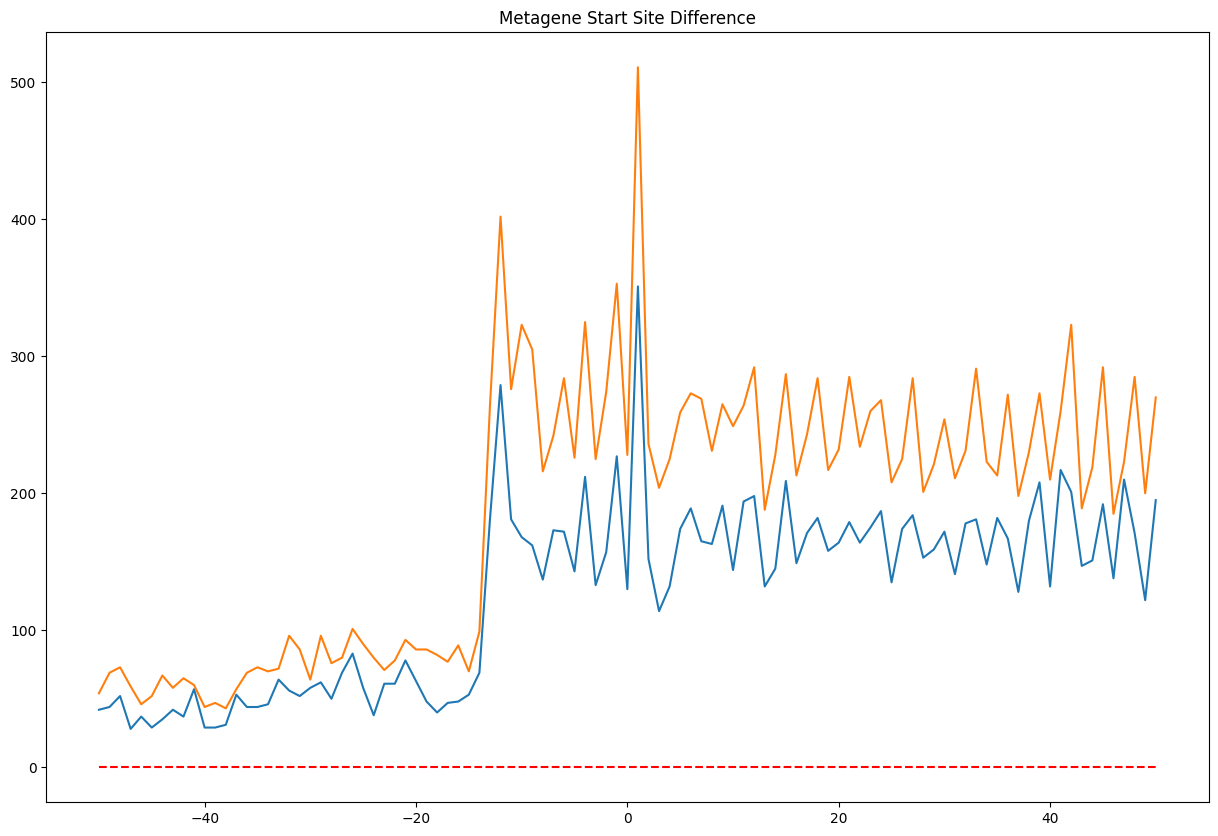

In [17]:
fig, ax = matplotlib.pyplot.subplots()
ax.plot((metagene_start_4 - metagene_start_3).loc["GSM1606107"])
ax.plot((metagene_start_4 - metagene_start_3).loc["GSM1606108"])
ax.hlines(y=0, xmin=-50, xmax = 50, color='r', linestyle='--');
plt.title("Metagene Start Site Difference");

In [18]:
metagene_stop_3 = \
   ribo_3.get_metagene(site_type      = "stop",
                       range_lower    = 28,
                       range_upper    = 32,
                       sum_lengths    = True,
                       sum_references = True
                      ).astype("int64").rename(index = strip_version)

metagene_stop_4 = \
   ribo_4.get_metagene(site_type      = "stop",
                       range_lower    = 28,
                       range_upper    = 32,
                       sum_lengths    = True,
                       sum_references = True
                      ).astype("int64").rename(index = strip_version)

stop_difference = metagene_stop_4 - metagene_stop_3

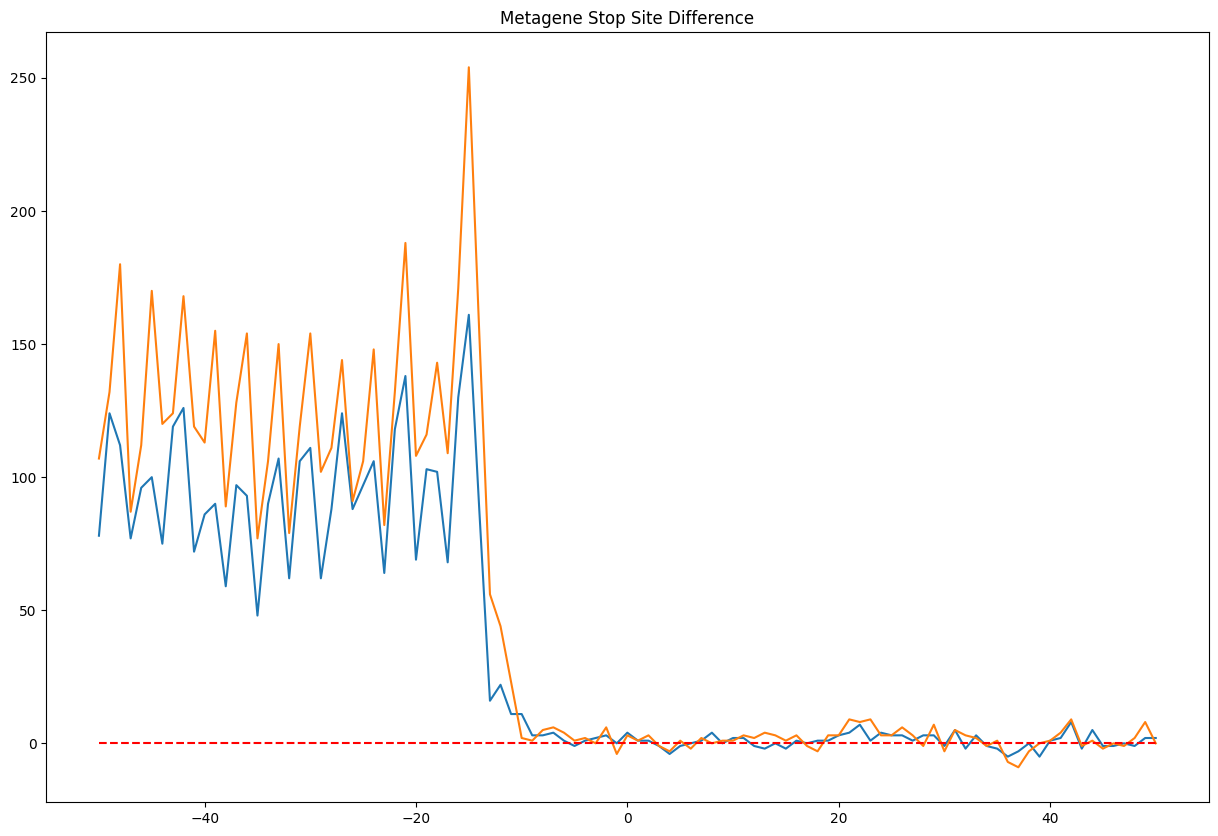

In [19]:
fig, ax = matplotlib.pyplot.subplots()
ax.plot((stop_difference).loc["GSM1606107"])
ax.plot((stop_difference).loc["GSM1606108"])
ax.hlines(y = 0, xmin = -50, xmax = 50, color = 'r', linestyle = '--');
plt.title("Metagene Stop Site Difference");

### Region Counts

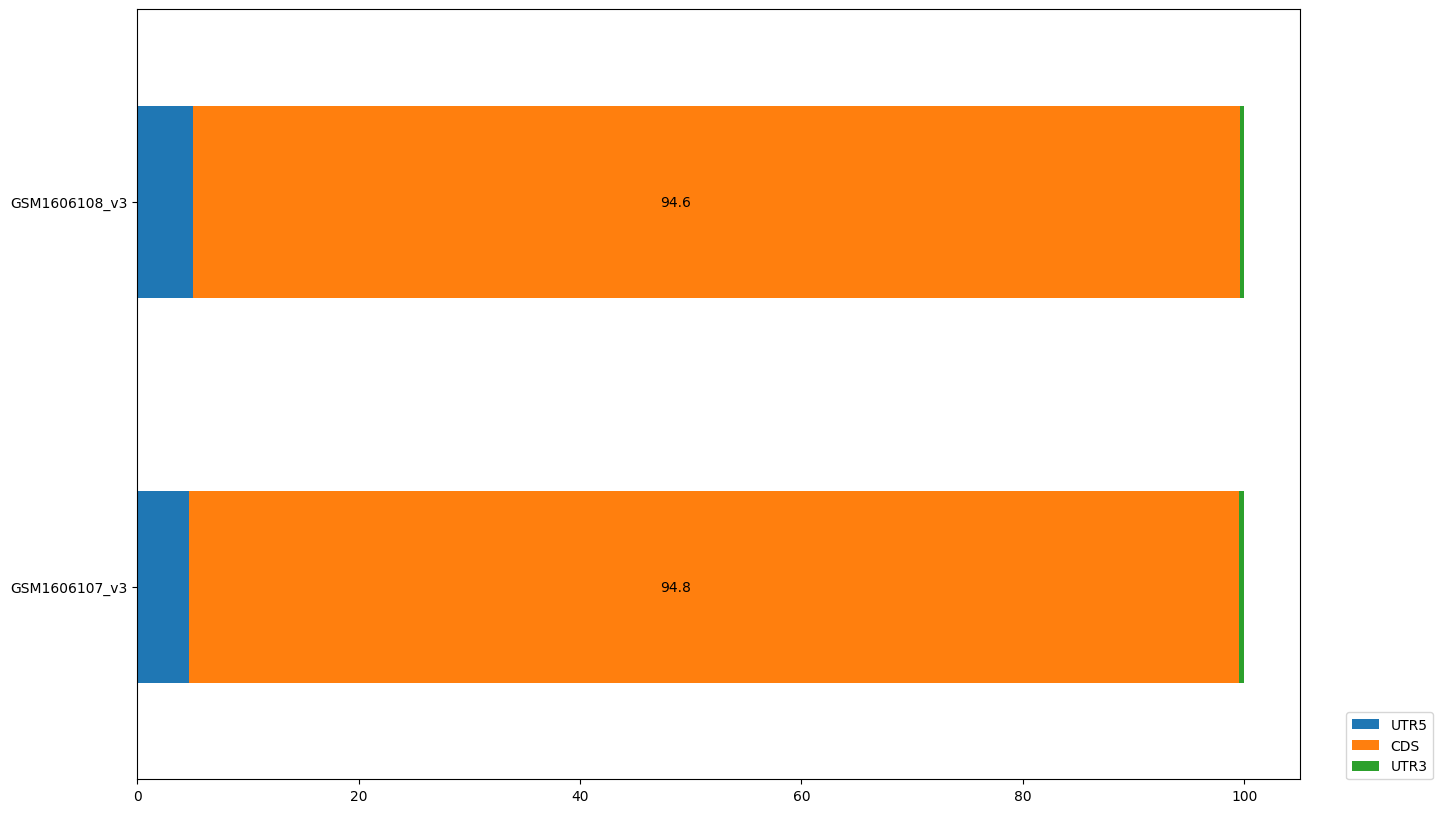

In [20]:
ribo_3.plot_region_counts(experiments = ["GSM1606107_v3", "GSM1606108_v3"],
                          range_lower = 28,
                          range_upper = 32,
                          horizontal  = True);

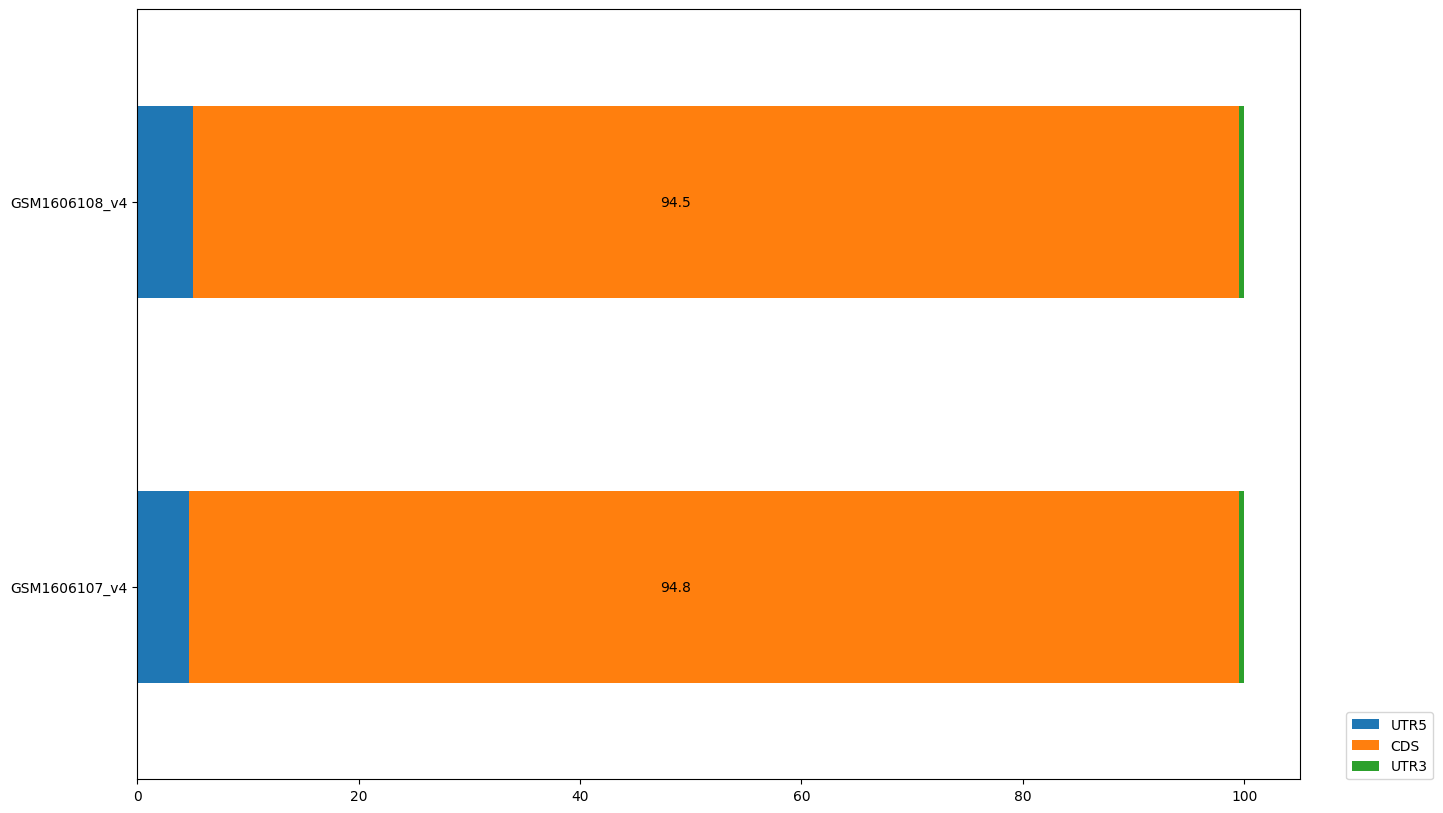

In [21]:
ribo_4.plot_region_counts(experiments = ["GSM1606107_v4", "GSM1606108_v4"],
                          range_lower = 28,
                          range_upper = 32,
                          horizontal  = True);

The v2 vs v3 comparison indexes the CDS counts by transcript name (`alias = True`, e.g. `MATR3-201`).
Many names and ENST versions change between GENCODE v48 and v50, so here we index by the Ensembl
transcript ID without the version, and keep the gene name in a column.

In [22]:
cds_3 = ribo_3.get_region_counts(experiments    = ["GSM1606107_v3", "GSM1606108_v3"],
                                 region_name    = "CDS",
                                 range_lower    = 28,
                                 range_upper    = 32,
                                 sum_lengths    = True,
                                 alias          = False,
                                 sum_references = False)

cds_4 = ribo_4.get_region_counts(experiments    = ["GSM1606107_v4", "GSM1606108_v4"],
                                 region_name    = "CDS",
                                 range_lower    = 28,
                                 range_upper    = 32,
                                 sum_lengths    = True,
                                 alias          = False,
                                 sum_references = False)

for cds in (cds_3, cds_4):
    cds.columns = ["GSM1606107", "GSM1606108"]
    cds["gene"] = [n.split("|")[5] for n in cds.index]
    cds.index   = [n.split("|")[0].split(".")[0] for n in cds.index]

In [23]:
common_genes = sorted(set(cds_3.index).intersection(set(cds_4.index)))
cds_3_common = cds_3.loc[common_genes]["GSM1606107"]
cds_4_common = cds_4.loc[common_genes]["GSM1606107"]

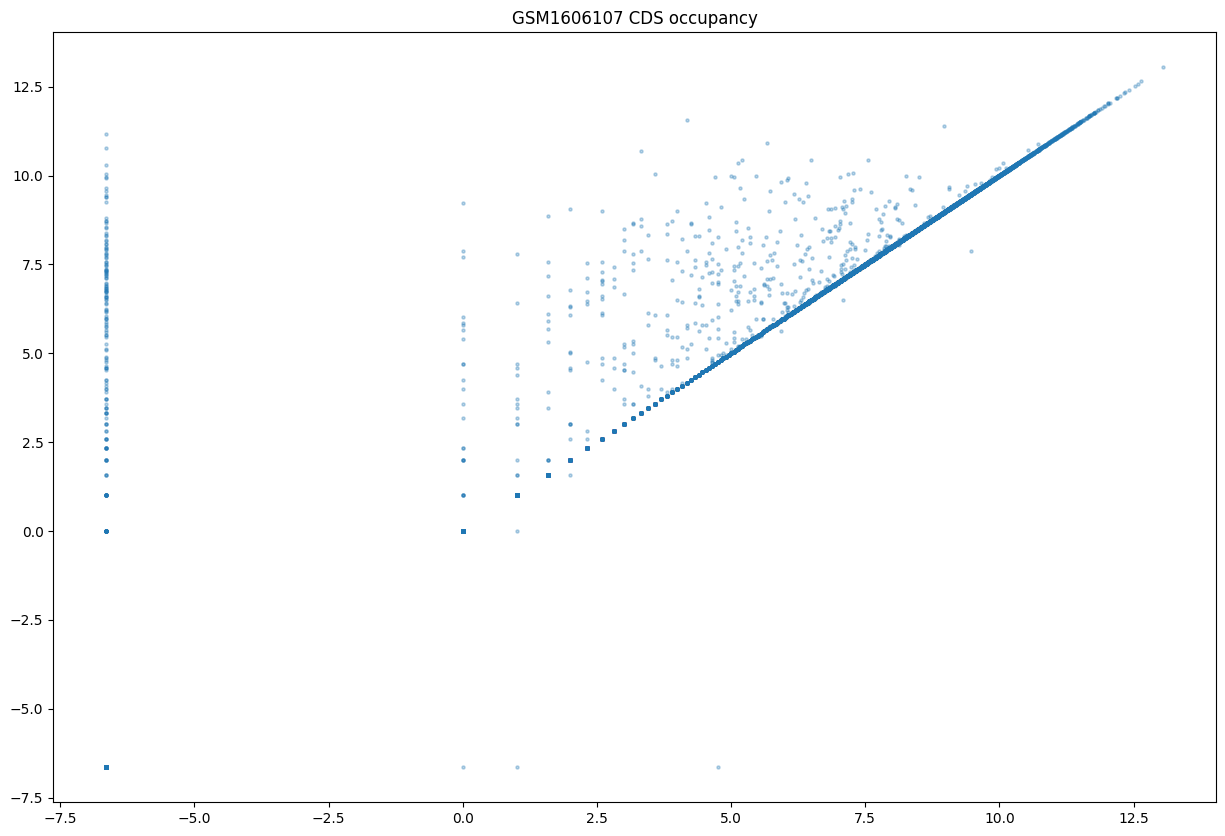

In [24]:
cds_3_log_counts = np.log2(np.array(cds_3_common) + 0.01)
cds_4_log_counts = np.log2(np.array(cds_4_common) + 0.01)

matplotlib.pyplot.scatter( cds_3_log_counts, cds_4_log_counts, alpha = 0.3, s = 5 );
plt.title("GSM1606107 CDS occupancy");

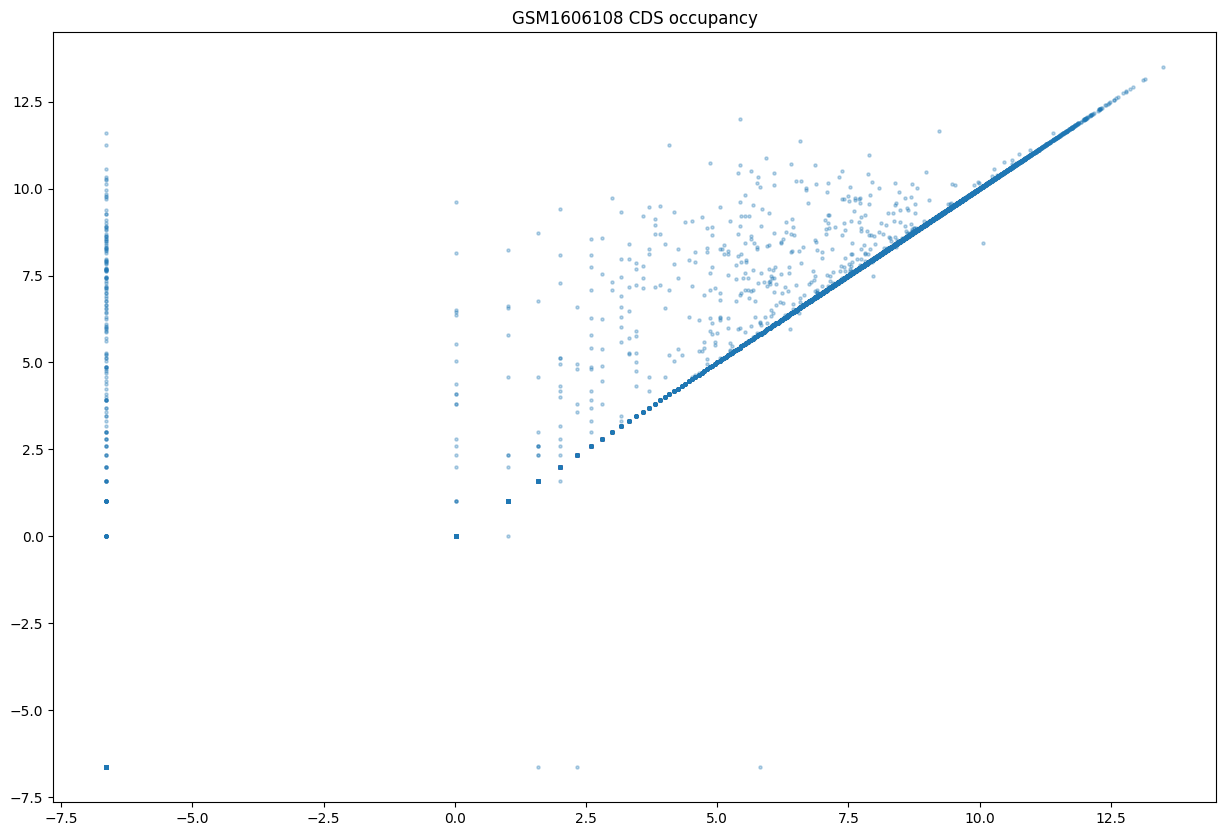

In [25]:
cds_3_common = cds_3.loc[common_genes]["GSM1606108"]
cds_4_common = cds_4.loc[common_genes]["GSM1606108"]

cds_3_log_counts = np.log2(np.array(cds_3_common) + 0.01)
cds_4_log_counts = np.log2(np.array(cds_4_common) + 0.01)

matplotlib.pyplot.scatter( cds_3_log_counts, cds_4_log_counts, alpha = 0.3, s = 5 );
plt.title("GSM1606108 CDS occupancy");

In [26]:
merged_cds = cds_3.merge(cds_4,
                         left_index  = True,
                         right_index = True,
                         suffixes    = ["_3", "_4"])

In [27]:
merged_cds["107_diff"] = pd.Series(merged_cds["GSM1606107_4"], dtype='int32') - \
                         pd.Series(merged_cds["GSM1606107_3"], dtype='int32')
merged_cds["108_diff"] = pd.Series(merged_cds["GSM1606108_4"], dtype='int32') - \
                         pd.Series(merged_cds["GSM1606108_3"], dtype='int32')
merged_cds["107_abs"]  = np.absolute(merged_cds["107_diff"])
merged_cds["108_abs"]  = np.absolute(merged_cds["108_diff"])

In [28]:
merged_cds.sort_values(by = ["107_abs"], ascending = False, inplace = True)
merged_cds

,GSM1606107_3,GSM1606108_3,gene_3,GSM1606107_4,GSM1606108_4,gene_4,107_diff,108_diff,107_abs,108_abs
ENST00000394805,18,43,MATR3,3040,4143,MATR3,3022,4100,3022,4100
ENST00000329251,0,0,EEF1G,2318,3135,EEF1G,2318,3135,2318,3135
ENST00000350669,499,595,LDHB,2693,3250,LDHB,2194,2655,2194,2655
ENST00000369622,51,95,SYNCRIP,1916,2649,SYNCRIP,1865,2554,1865,2554
ENST00000396172,0,0,DDX39B,1745,2450,DDX39B,1745,2450,1745,2450
...,...,...,...,...,...,...,...,...,...,...
ENST00000454853,0,0,GABRR1,0,0,GABRR1,0,0,0,0
ENST00000402938,1,0,GABRR2,1,0,GABRR2,0,0,0,0
ENST00000435041,292,441,UBE2J1,292,441,UBE2J1,0,0,0,0
ENST00000369415,114,191,RRAGD,114,191,RRAGD,0,0,0,0


In [29]:
merged_cds[ merged_cds["107_abs"] > 5 ]

,GSM1606107_3,GSM1606108_3,gene_3,GSM1606107_4,GSM1606108_4,gene_4,107_diff,108_diff,107_abs,108_abs
ENST00000394805,18,43,MATR3,3040,4143,MATR3,3022,4100,3022,4100
ENST00000329251,0,0,EEF1G,2318,3135,EEF1G,2318,3135,2318,3135
ENST00000350669,499,595,LDHB,2693,3250,LDHB,2194,2655,2194,2655
ENST00000369622,51,95,SYNCRIP,1916,2649,SYNCRIP,1865,2554,1865,2554
ENST00000396172,0,0,DDX39B,1745,2450,DDX39B,1745,2450,1745,2450
...,...,...,...,...,...,...,...,...,...,...
ENST00000429814,0,0,TRIM34,6,4,TRIM34,6,4,6,4
ENST00000677315,0,0,ENSG00000288661,6,5,ENSG00000288661,6,5,6,5
ENST00000312492,0,5,HOXC5,6,12,HOXC5,6,7,6,7
ENST00000216252,193,345,PHF5A,199,365,PHF5A,6,20,6,20


In [30]:
merged_cds[ merged_cds["107_abs"] > 100 ]

,GSM1606107_3,GSM1606108_3,gene_3,GSM1606107_4,GSM1606108_4,gene_4,107_diff,108_diff,107_abs,108_abs
ENST00000394805,18,43,MATR3,3040,4143,MATR3,3022,4100,3022,4100
ENST00000329251,0,0,EEF1G,2318,3135,EEF1G,2318,3135,2318,3135
ENST00000350669,499,595,LDHB,2693,3250,LDHB,2194,2655,2194,2655
ENST00000369622,51,95,SYNCRIP,1916,2649,SYNCRIP,1865,2554,1865,2554
ENST00000396172,0,0,DDX39B,1745,2450,DDX39B,1745,2450,1745,2450
...,...,...,...,...,...,...,...,...,...,...
ENST00000397130,4,8,LRRC57,109,158,LRRC57,105,150,105,150
ENST00000452699,185,284,ATP13A2,289,418,ATP13A2,104,134,104,134
ENST00000272930,25,41,UBE2F,127,168,UBE2F,102,127,102,127
ENST00000276704,27,51,C8orf76,129,201,C8orf76,102,150,102,150


In [31]:
for a in merged_cds[ merged_cds["107_abs"] > 50 ].index:
    print(a, merged_cds.loc[a, "gene_4"])

ENST00000394805 MATR3
ENST00000329251 EEF1G
ENST00000350669 LDHB
ENST00000369622 SYNCRIP
ENST00000396172 DDX39B
ENST00000360839 ANKHD1
ENST00000378823 RAD50
ENST00000648437 RPS10
ENST00000481195 PPP2CA
ENST00000223321 PSMA2
ENST00000264932 SDHA
ENST00000512737 NME2
ENST00000322166 NOP2
ENST00000353411 SKP1
ENST00000656825 CDC42
ENST00000361188 PRC1
ENST00000647841 RPS17
ENST00000354926 LUC7L2
ENST00000258962 SRSF1
ENST00000623063 ADSL
ENST00000266544 NDUFA9
ENST00000301785 HNRNPUL2
ENST00000261479 PSMA6
ENST00000580261 RPL17
ENST00000003100 CYP51A1
ENST00000396394 PSMA1
ENST00000287844 ABCF2
ENST00000553110 RPL36A
ENST00000347839 KLC1
ENST00000648839 RPL26
ENST00000395443 QRICH1
ENST00000356476 H3C4
ENST00000215829 SNRPD3
ENST00000614556 DCAF7
ENST00000265271 RBM27
ENST00000418115 RHOA
ENST00000244020 SRSF6
ENST00000299166 NDUFB8
ENST00000396832 CSNK1E
ENST00000262518 SRCAP
ENST00000341023 H2AC7
ENST00000262942 ARPC1A
ENST00000652027 TSFM
ENST00000714045 VPS33A
ENST00000393196 NME1
ENS

### Do the removed transcripts explain the differences?

`v3/riboflow_annot_and_ref/containment/overlap_fraction.tsv` lists, for every v3 transcript, what it
shared sequence with: a read-through gene, a transcript it is contained in, only transcripts that v4
removes, another kept transcript, or nothing.

If a transcript only overlapped transcripts that v4 removes, its reads were multimappers in v3 and
are unique in v4. We expect it to gain reads.

In [32]:
ov = pd.read_csv(V3_OVERLAP, sep="\t")
ov.index = ov.tx.str.split(".").str[0]

merged_cds["v3_category"] = ov.category.reindex(merged_cds.index).fillna("No overlap")
merged_cds.loc[merged_cds.index.isin(bicistronic.transcript), "v3_category"] = "Bicistronic pair"

big = merged_cds[ merged_cds["107_abs"] > 50 ]
print(f"{len(big)} transcripts shift by > 50 CDS reads in GSM1606107, by their v3 overlap category:")
print(big.v3_category.value_counts().to_string(), "\n")
print("sign of the shift within each category (positive = more reads in v4):")
big.groupby("v3_category")["107_diff"].agg(["count", "min", "median", "max"]).round(0)

347 transcripts shift by > 50 CDS reads in GSM1606107, by their v3 overlap category:
v3_category
Overlaps only removed transcripts    327
Overlaps another kept transcript       9
No overlap                             6
Entirely contained                     4
Bicistronic pair                       1 

sign of the shift within each category (positive = more reads in v4):


,count,min,median,max
v3_category,,,,
Bicistronic pair,1,154,154.0,154
Entirely contained,4,315,326.0,1745
No overlap,6,-479,70.0,257
Overlaps another kept transcript,9,77,221.0,609
Overlaps only removed transcripts,327,53,168.0,3022


In [33]:
# the shifts NOT explained by a removed overlapping transcript
cols = ["gene_4", "GSM1606107_3", "GSM1606107_4", "107_diff", "GSM1606108_3", "GSM1606108_4", "108_diff"]
big[big.v3_category.isin(["No overlap", "Overlaps another kept transcript"])][cols + ["v3_category"]]

,gene_4,GSM1606107_3,GSM1606107_4,107_diff,GSM1606108_3,GSM1606108_4,108_diff,v3_category
ENST00000262518,SRCAP,38,647,609,56,1068,1012,Overlaps another kept transcript
ENST00000253107,PPAN,64,606,542,104,1030,926,Overlaps another kept transcript
ENST00000340852,HM13,713,234,-479,1076,349,-727,No overlap
ENST00000375882,CSNK2B,329,773,444,447,1042,595,Overlaps another kept transcript
ENST00000406360,FOXO3,104,361,257,140,606,466,No overlap
ENST00000443786,HAUS3,37,293,256,50,373,323,Overlaps another kept transcript
ENST00000320330,PAGR1,0,221,221,0,378,378,Overlaps another kept transcript
ENST00000593646,RNASEK,223,416,193,277,512,235,Overlaps another kept transcript
ENST00000225519,SHPK,0,178,178,0,285,285,Overlaps another kept transcript
ENST00000715811,ENSG00000293606,0,146,146,0,235,235,Overlaps another kept transcript


In [34]:
# the bicistronic pairs: the dropped member is not in v4, the kept member gets the reads
bicistronic.assign(GSM1606107_3 = bicistronic.transcript.map(cds_3["GSM1606107"]),
                   GSM1606107_4 = bicistronic.transcript.map(cds_4["GSM1606107"]),
                   GSM1606108_3 = bicistronic.transcript.map(cds_3["GSM1606108"]),
                   GSM1606108_4 = bicistronic.transcript.map(cds_4["GSM1606108"]))

,transcript,gene,CDS,CDS length,kept in v4,GSM1606107_3,GSM1606107_4,GSM1606108_3,GSM1606108_4
0,ENST00000273968,PYURF,77-421,345,True,0,154.0,0,205.0
1,ENST00000527353,PIGY,520-735,216,False,0,NaN,0,NaN
2,ENST00000715679,ENSG00000293600,17-328,312,False,0,NaN,0,NaN
3,ENST00000323146,SLC35A4,736-1710,975,True,0,11.0,0,24.0
4,ENST00000578372,SMIM10L3,210-416,207,False,0,NaN,0,NaN
5,ENST00000313324,FAM220A,477-1256,780,True,0,27.0,0,49.0
6,ENST00000247005,GDF1,1409-2527,1119,True,0,0.0,0,3.0
7,ENST00000623882,CERS1,87-1139,1053,False,0,NaN,0,NaN


**QC is the same.** Length distribution, metagene shape, periodicity and region proportions do not
change. v4 keeps about 3.2% more CDS reads at every read length. The metagene difference is positive
and flat across the CDS, so reads are gained everywhere, not at specific positions.

**Where the reads come from.** 347 transcripts change by more than 50 CDS reads in GSM1606107.
327 of them (94%) only overlapped transcripts that v4 removes. Most share exons with a read-through gene,
for example MATR3 (18 to 3040), EEF1G (0 to 2318) and LDHB (499 to 2693). In v3 their reads also mapped
to the read-through and were discarded. In v4 they map uniquely. All 327 are gains
(median +168). The 4 contained transcripts and the bicistronic representative PYURF (0 to 154) gain for
the same reason.

**Not explained by removals.** 15 transcripts. Most are moderate gains in genes that share sequence with a
paralog (SRCAP, PPAN, CSNK2B, FOXO3, HAUS3). One is a loss, HM13 (713 to 234). A few got a different
isoform between GENCODE v48 and v50 (PAGR1, SHPK, CD99 go from 0 to more than 50).

**Bicistronic pairs.** All eight members had 0 CDS reads in v3, because every read was a multimapper.
In v4 the kept members get the reads: PYURF 154 / 205, FAM220A 27 / 49, SLC35A4 11 / 24, GDF1 0 / 3.

## Summary

| change | v3 | v4 | recoverable? |
|---|---|---|---|
| read-through genes | kept | removed (665, Step 3) | no |
| transcripts inside a longer one | kept | removed (Step 5) | not needed, the sequence is in the kept one |
| bicistronic pairs | both kept | keep the longer CDS (PYURF, SLC35A4, FAM220A, GDF1) | no, the shorter ORF is not counted |
| mapping (GSM1606107 / GSM1606108) | | same QC, 3.2% more CDS reads, 347 transcripts change by more than 50 reads and 332 of them are explained by the removals | |